# ПР-2. Разведочный анализ данных (EDA)
Датасет: Give Me Some Credit. Цель: найти проблемы в данных, проверить гипотезы, оценить риск утечки.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("../data/cs-training.csv", index_col=0)

# короткие имена для удобства (только внутри этого notebook)
df = df.rename(columns={
    "SeriousDlqin2yrs": "default",
    "RevolvingUtilizationOfUnsecuredLines": "utilization",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59",
    "DebtRatio": "debt_ratio",
    "MonthlyIncome": "income",
    "NumberOfOpenCreditLinesAndLoans": "open_credits",
    "NumberOfTimes90DaysLate": "late_90",
    "NumberRealEstateLoansOrLines": "real_estate",
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89",
    "NumberOfDependents": "dependents",
})
df.head()

,default,utilization,age,late_30_59,debt_ratio,income,open_credits,late_90,real_estate,late_60_89,dependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
print("Возраст = 0:", (df["age"] == 0).sum())
print("Возраст < 18:", (df["age"] < 18).sum())
print("utilization > 1:", (df["utilization"] > 1).sum())
print("debt_ratio > 10:", (df["debt_ratio"] > 10).sum())
print("Значения 96 и 98 в просрочках:")
for col in ["late_30_59", "late_60_89", "late_90"]:
    print(" ", col, df[col].isin([96, 98]).sum())
print("income = 0:", (df["income"] == 0).sum())

Возраст = 0: 1
Возраст < 18: 1
utilization > 1: 3321
debt_ratio > 10: 28877
Значения 96 и 98 в просрочках:
  late_30_59 269
  late_60_89 269
  late_90 269
income = 0: 1634


In [3]:
df_clean = df.copy()
df_clean.loc[df_clean["age"] == 0, "age"] = np.nan
for col in ["late_30_59", "late_60_89", "late_90"]:
    df_clean.loc[df_clean[col].isin([96, 98]), col] = np.nan

Возраст 0 невозможен для заёмщика, а значения 96 и 98 в столбцах просрочек выглядят как служебные коды (реальных клиентов с 98 просрочками быть не может). Эти значения помечены как пропуски в копии df_clean, исходные данные не изменены.

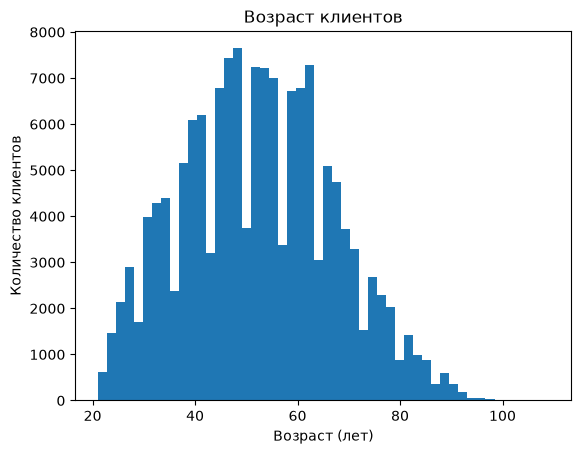

In [4]:
df_clean["age"].plot(kind="hist", bins=50)
plt.title("Возраст клиентов")
plt.xlabel("Возраст (лет)")
plt.ylabel("Количество клиентов")
plt.show()

Основная масса клиентов имеет возраст от 30 до 70 лет, чаще всего встречаются люди около 45–60 лет. Молодых и очень пожилых клиентов мало. После замены возраста 0 на пропуск аномальных значений на графике не видно. Зубцы на гистограмме связаны с тем, что возраст целое число, а не с проблемой данных.

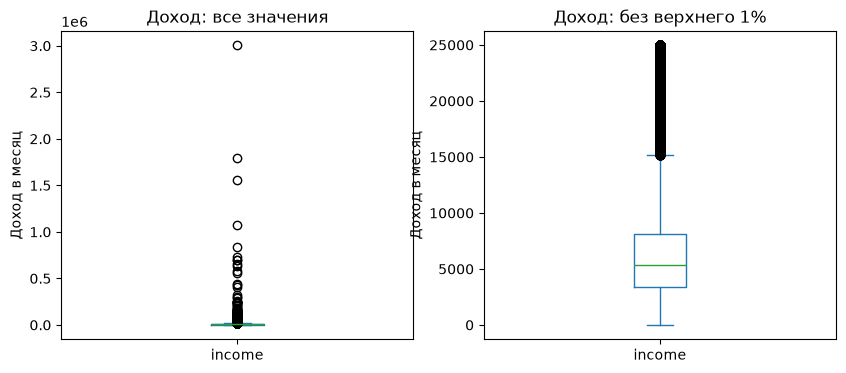

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["income"].dropna().plot(kind="box", ax=axes[0])
axes[0].set_title("Доход: все значения")
axes[0].set_ylabel("Доход в месяц")
limit = df["income"].quantile(0.99)
df.loc[df["income"] <= limit, "income"].plot(kind="box", ax=axes[1])
axes[1].set_title("Доход: без верхнего 1%")
axes[1].set_ylabel("Доход в месяц")
plt.show()

Доход сильно скошен: у большинства клиентов он около 3 400–8 200 в месяц (медиана примерно 5 400), но у отдельных клиентов достигает миллионов, из-за чего на левом графике ящик не виден. Даже после отбрасывания верхнего 1% остаётся много высоких значений (выше примерно 15 000). Это не обязательно ошибки, но такие значения могут сильно влиять на модель. Решение, что с ними делать, будет принято позже и с обоснованием.

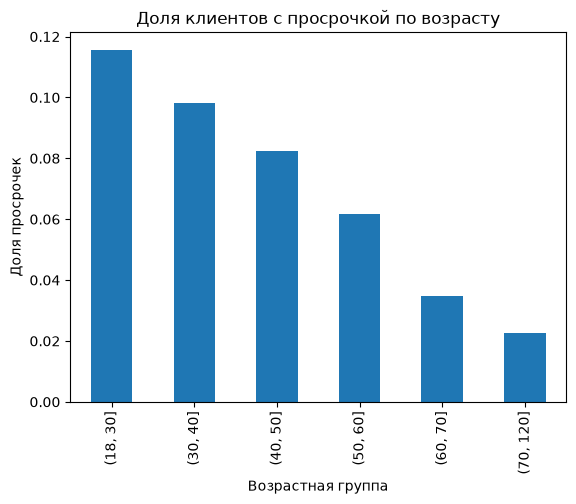

In [6]:
groups = pd.cut(df_clean["age"], bins=[18, 30, 40, 50, 60, 70, 120])
rate = df_clean.groupby(groups, observed=True)["default"].mean()
rate.plot(kind="bar")
plt.title("Доля клиентов с просрочкой по возрасту")
plt.xlabel("Возрастная группа")
plt.ylabel("Доля просрочек")
plt.show()

Доля клиентов с просрочкой последовательно снижается с возрастом: от примерно 11–12% в группе до 30 лет до примерно 2% в группе старше 70 лет. Это связь, но не доказательство причины: возможно, на неё влияют другие факторы (например, у пожилых больше стабильного дохода или меньше кредитов).

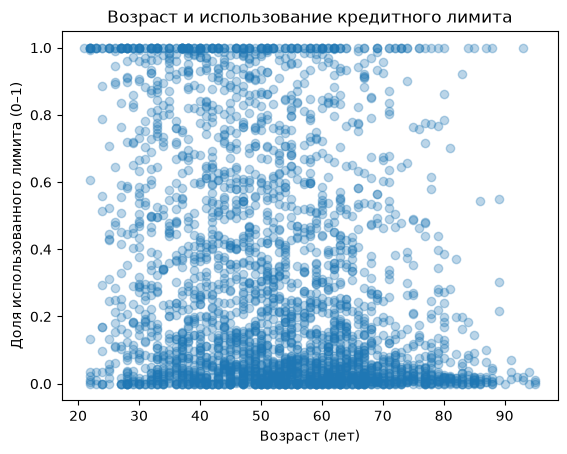

In [7]:
sample = df_clean[df_clean["utilization"] <= 1].sample(3000, random_state=42)
plt.scatter(sample["age"], sample["utilization"], alpha=0.3)
plt.title("Возраст и использование кредитного лимита")
plt.xlabel("Возраст (лет)")
plt.ylabel("Доля использованного лимита (0–1)")
plt.show()

Явной зависимости между возрастом и использованием лимита нет, точки разбросаны по всему графику. Видно, что у пожилых клиентов (после 70 лет) использование лимита в основном низкое, а у молодых встречаются и очень высокие значения. Для графика взято 3000 случайных клиентов с использованием лимита не больше 1, иначе точки слились бы в сплошное пятно.

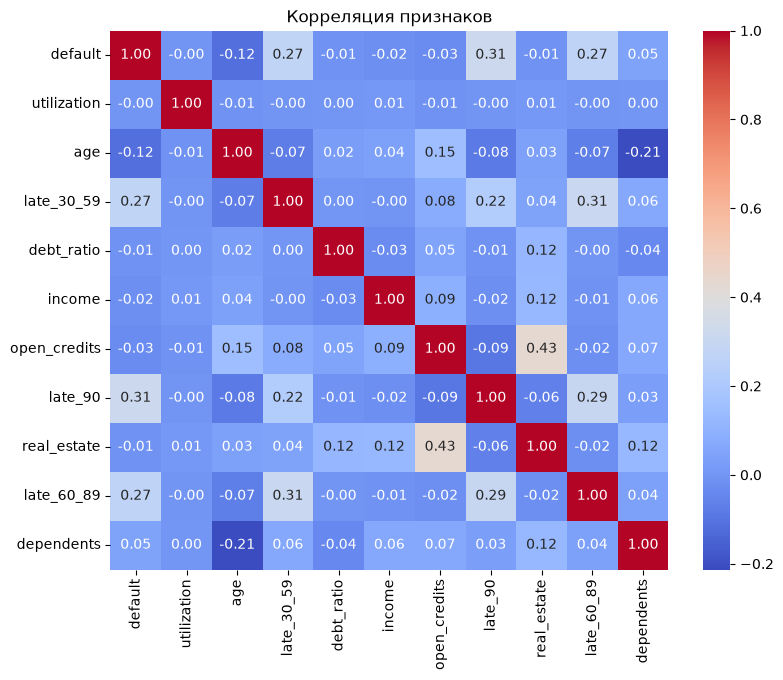

In [8]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_clean.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Корреляция признаков")
plt.show()

Линейная корреляция utilization с просрочкой на heatmap близка к 0, но это артефакт выбросов (максимум 50 708 при нормальном диапазоне 0–1). Без выбросов корреляция равна 0,25, а ранговая корреляция Спирмена 0,24. Значит, использование кредитного лимита связано с просрочкой не слабее, чем признаки прошлых просрочек. Выбросы скрыли эту связь.

In [9]:
ok = df_clean[df_clean["utilization"] <= 1]
print("Корреляция с просрочкой без выбросов:", ok["utilization"].corr(ok["default"]))
print("Корреляция по рангам (не боится выбросов):", df_clean["utilization"].corr(df_clean["default"], method="spearman"))

Корреляция с просрочкой без выбросов: 0.24944601598337898
Корреляция по рангам (не боится выбросов): 0.24037817700357894


In [10]:
a = df_clean.loc[df_clean["default"] == 1, "age"].dropna()
b = df_clean.loc[df_clean["default"] == 0, "age"].dropna()
print("Средний возраст должников:", a.mean())
print("Средний возраст остальных:", b.mean())
print(stats.ttest_ind(a, b, equal_var=False))

Средний возраст должников: 45.92659086375424
Средний возраст остальных: 52.751752123623845
TtestResult(statistic=np.float64(-50.587785393976226), pvalue=np.float64(0.0), df=np.float64(11989.013919661329))


**Гипотеза 1:** должники в среднем моложе остальных клиентов.
**Тест:** t-тест (Уэлча), так как сравниваются средние значения числового признака в двух группах.
**Результат:** средний возраст должников 45,9 года, остальных клиентов 52,8 года; p-value близко к 0.
**Вывод:** гипотеза подтверждается. Разница составляет около 6,8 года и не является случайной. Это связь, а не доказательство причины.

In [11]:
a = df_clean.loc[df_clean["default"] == 1, "income"].dropna()
b = df_clean.loc[df_clean["default"] == 0, "income"].dropna()
print("Медианный доход должников:", a.median())
print("Медианный доход остальных:", b.median())
print(stats.mannwhitneyu(a, b))

Медианный доход должников: 4500.0
Медианный доход остальных: 5466.0
MannwhitneyuResult(statistic=np.float64(396509299.5), pvalue=np.float64(2.354241453776735e-119))


**Гипотеза 2:** у клиентов с просрочкой доход ниже, чем у остальных.
**Тест:** критерий Манна-Уитни, так как доход сильно скошен (см. boxplot) и содержит выбросы, поэтому t-тест для него менее подходит.
**Результат:** медианный доход должников 4 500, остальных 5 466; p-value примерно 2·10⁻¹¹⁹.
**Вывод:** гипотеза подтверждается: у должников доход в среднем ниже примерно на 18%. Тест использует только клиентов с известным доходом (около 20% значений пропущено), поэтому вывод относится к ним.

In [12]:
tmp = df_clean.dropna(subset=["late_90"])
table = pd.crosstab(tmp["late_90"] > 0, tmp["default"])
print(table)
print("Доля просрочек у тех, кто просрочивал раньше:", table.loc[True, 1] / table.loc[True].sum())
print("Доля просрочек у остальных:", table.loc[False, 1] / table.loc[False].sum())
print(stats.chi2_contingency(table))

default       0     1
late_90              
False    135108  6554
True       4744  3325
Доля просрочек у тех, кто просрочивал раньше: 0.4120708885859462
Доля просрочек у остальных: 0.0462650534370544
Chi2ContingencyResult(statistic=np.float64(16571.005874451796), pvalue=np.float64(0.0), dof=1, expected_freq=array([[132315.37907314,   9346.62092686],
       [  7536.62092686,    532.37907314]]))


**Гипотеза 3:** клиенты, у которых уже была просрочка 90+ дней, чаще допускают просрочку снова.
**Тест:** хи-квадрат, так как оба признака категориальные (было / не было просрочки).
**Результат:** среди клиентов с прошлой просрочкой 90+ дней снова просрочку допустили 41,2%, среди остальных 4,6% (разница примерно в 9 раз); p-value близко к 0.
**Вывод:** гипотеза подтверждается, связь очень сильная. Из проверки исключены 269 строк со служебными кодами 96/98. Из-за этой сильной связи нужно проверить риск утечки данных (период, за который считался признак late_90, в описании датасета не указан).

**Риски утечки данных:**
1. В описании датасета не указан период, за который рассчитаны признаки просрочек. Если он пересекается с периодом целевой переменной (2 года), признаки late_30_59, late_60_89 и late_90 могут содержать информацию о результате.
2. Пропуски в income и dependents нужно заполнять только по статистикам обучающей выборки, а не всего датасета, иначе информация из тестовой части попадёт в обучающую.

**Предположение о важных признаках:** наиболее значимыми, вероятно, будут признаки прошлых просрочек (late_90, late_30_59, late_60_89, корреляции 0,27–0,31), использование кредитного лимита utilization (корреляция 0,25 после исключения выбросов) и возраст (-0,12). Остальные признаки связаны с целевой переменной слабо. Это предположение будет проверено моделями в следующих работах.

## Список проблем данных
| № | Проблема | Где обнаружена | Как планируется устранить |
|---|---|---|---|
| 1 | Дисбаланс классов: около 6,7% просрочек (1:14) | график целевой переменной | class_weight или SMOTE (ПР-5) |
| 2 | Пропуски: income около 19,8% (29 731 строка), dependents около 2,6% (3 924 строки) | info(), график пропусков | заполнить медианой внутри пайплайна |
| 3 | Возраст 0 (невозможное значение) в 1 строке | describe(), гистограмма возраста | заменить на пропуск и заполнить медианой |
| 4 | Служебные коды 96/98 в столбцах late_30_59, late_60_89 и late_90 (по 269 строк в каждом) | describe(), проверка аномалий | заменить на пропуск, затем заполнить |
| 5 | Выбросы utilization: в 3 321 строке значение больше 1 (максимум 50 708, норма 0–1) | describe(), корреляция | ограничить значения сверху |
| 6 | Выбросы debt_ratio: в 28 877 строках значение больше 10 (максимум 329 664) | describe() | ограничить значения сверху |
| 7 | Сильно скошенный доход с экстремальными значениями (до 3 млн), в 1 634 строках доход равен 0 | boxplot дохода, проверка аномалий | ограничить сверху или логарифмировать; нули проверить отдельно |
| 8 | Признаки просрочек коррелируют между собой (0,22–0,31) | heatmap | учесть при выборе признаков в моделях |
| 9 | Риск утечки: период признаков просрочек не указан | анализ описания датасета | заполнять пропуски только по train |

In [13]:
  mask = df["late_30_59"].isin([96, 98]) & df["late_60_89"].isin([96, 98]) & df["late_90"].isin([96, 98])
  print("Строк с кодами во всех трёх столбцах:", mask.sum())

Строк с кодами во всех трёх столбцах: 269
